In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv("metaverse_transactions_dataset.csv")
df

,timestamp,hour_of_day,sending_address,receiving_address,amount,transaction_type,location_region,ip_prefix,login_frequency,session_duration,purchase_pattern,age_group,risk_score,anomaly
0,2022-04-11 12:47:27,12,0x9d32d0bf2c00f41ce7ca01b66e174cc4dcb0c1da,0x39f82e1c09bc6d7baccc1e79e5621ff812f50572,796.949206,transfer,Europe,192.000,3,48,focused,established,18.7500,low_risk
1,2022-06-14 19:12:46,19,0xd6e251c23cbf52dbd472f079147873e655d8096f,0x51e8fbe24f124e0e30a614e14401b9bbfed5384c,0.010000,purchase,South America,172.000,5,61,focused,established,25.0000,low_risk
2,2022-01-18 16:26:59,16,0x2e0925b922fed01f6a85d213ae2718f54b8ca305,0x52c7911879f783d590af45bda0c0ef2b8536706f,778.197390,purchase,Asia,192.168,3,74,focused,established,31.2500,low_risk
3,2022-06-15 09:20:04,9,0x93efefc25fcaf31d7695f28018d7a11ece55457f,0x8ac3b7bd531b3a833032f07d4e47c7af6ea7bace,300.838358,transfer,South America,172.000,8,111,high_value,veteran,36.7500,low_risk
4,2022-02-18 14:35:30,14,0xad3b8de45d63f5cce28aef9a82cf30c397c6ceb9,0x6fdc047c2391615b3facd79b4588c7e9106e49f2,775.569344,sale,Africa,172.160,6,100,high_value,veteran,62.5000,moderate_risk
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78595,2022-02-13 12:52:27,12,0xa99b9a7f5c5dd37429771efd3b93c6fbe1ab2936,0x5a78c88c5fc1e9b512f6c64e266b46a9db0a7238,660.280373,transfer,Africa,172.000,1,27,random,new,26.2500,low_risk
78596,2022-02-16 16:15:29,16,0xcca095ad2d508c200bda1141f783d77c3e6cbb08,0xb71a4df291ea8e9996a74e77ab63f5abcbfe90f5,310.273397,purchase,Africa,172.000,5,60,focused,established,26.2500,low_risk
78597,2022-08-04 16:06:42,16,0xe0b340171486b08f0c1f4ac607ed776478cefd2b,0x577754308538f4be10a41afb4f8900cd24d7098f,624.674332,purchase,Africa,192.000,1,34,random,new,36.7500,low_risk
78598,2022-02-26 04:06:08,4,0xb0b2f6fc707fbb7f9d27a9f4fe0cb0d6b39a0155,0xd6ba299fdd52f09f01d9648036ca446498c01ac2,401.391592,purchase,Asia,192.168,4,56,focused,established,35.4375,low_risk


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78600 entries, 0 to 78599
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   timestamp          78600 non-null  object 
 1   hour_of_day        78600 non-null  int64  
 2   sending_address    78600 non-null  object 
 3   receiving_address  78600 non-null  object 
 4   amount             78600 non-null  float64
 5   transaction_type   78600 non-null  object 
 6   location_region    78600 non-null  object 
 7   ip_prefix          78600 non-null  float64
 8   login_frequency    78600 non-null  int64  
 9   session_duration   78600 non-null  int64  
 10  purchase_pattern   78600 non-null  object 
 11  age_group          78600 non-null  object 
 12  risk_score         78600 non-null  float64
 13  anomaly            78600 non-null  object 
dtypes: float64(3), int64(3), object(8)
memory usage: 8.4+ MB


In [4]:
df.describe()

,hour_of_day,amount,ip_prefix,login_frequency,session_duration,risk_score
count,78600.000000,78600.000000,78600.000000,78600.000000,78600.000000,78600.000000
mean,11.532634,502.574903,147.644430,4.178702,69.684606,44.956722
std,6.935897,245.898146,69.388143,2.366038,40.524476,21.775365
min,0.000000,0.010000,10.000000,1.000000,20.000000,15.000000
25%,6.000000,331.319966,172.000000,2.000000,35.000000,26.250000
50%,12.000000,500.029500,172.160000,4.000000,60.000000,40.000000
75%,18.000000,669.528311,192.000000,6.000000,100.000000,52.500000
max,23.000000,1557.150905,192.168000,8.000000,159.000000,100.000000


In [5]:
df.drop(
    columns=[
        'timestamp',
        'sending_address',
        'receiving_address',
        'transaction_type',
        'risk_score'
    ],
    inplace=True
)

df

,hour_of_day,amount,location_region,ip_prefix,login_frequency,session_duration,purchase_pattern,age_group,anomaly
0,12,796.949206,Europe,192.000,3,48,focused,established,low_risk
1,19,0.010000,South America,172.000,5,61,focused,established,low_risk
2,16,778.197390,Asia,192.168,3,74,focused,established,low_risk
3,9,300.838358,South America,172.000,8,111,high_value,veteran,low_risk
4,14,775.569344,Africa,172.160,6,100,high_value,veteran,moderate_risk
...,...,...,...,...,...,...,...,...,...
78595,12,660.280373,Africa,172.000,1,27,random,new,low_risk
78596,16,310.273397,Africa,172.000,5,60,focused,established,low_risk
78597,16,624.674332,Africa,192.000,1,34,random,new,low_risk
78598,4,401.391592,Asia,192.168,4,56,focused,established,low_risk


In [6]:
duplicated_rows = df[df.duplicated()]

# Display the duplicated rows
duplicated_rows

,hour_of_day,amount,location_region,ip_prefix,login_frequency,session_duration,purchase_pattern,age_group,anomaly
21280,3,0.01,Africa,192.168,1,24,random,new,low_risk
33500,18,0.01,Europe,192.000,2,28,random,new,low_risk
33800,17,0.01,North America,172.160,2,33,random,new,low_risk
43557,5,0.01,Europe,192.168,1,23,random,new,low_risk
48467,8,0.01,North America,192.000,2,36,random,new,low_risk
68970,15,0.01,Asia,172.000,1,36,random,new,low_risk


In [7]:
# Remove all duplicated rows based on all columns
df = df.drop_duplicates()

# Display the first few rows of the cleaned dataset
print(df.head())

   hour_of_day      amount location_region  ip_prefix  login_frequency  \
0           12  796.949206          Europe    192.000                3   
1           19    0.010000   South America    172.000                5   
2           16  778.197390            Asia    192.168                3   
3            9  300.838358   South America    172.000                8   
4           14  775.569344          Africa    172.160                6   

   session_duration purchase_pattern    age_group        anomaly  
0                48          focused  established       low_risk  
1                61          focused  established       low_risk  
2                74          focused  established       low_risk  
3               111       high_value      veteran       low_risk  
4               100       high_value      veteran  moderate_risk  


In [8]:
duplicated_rows = df[df.duplicated()]

# Display the duplicated rows
duplicated_rows

,hour_of_day,amount,location_region,ip_prefix,login_frequency,session_duration,purchase_pattern,age_group,anomaly


In [9]:
df.isnull().sum()

hour_of_day         0
amount              0
location_region     0
ip_prefix           0
login_frequency     0
session_duration    0
purchase_pattern    0
age_group           0
anomaly             0
dtype: int64

In [10]:
df['anomaly'].unique()

array(['low_risk', 'moderate_risk', 'high_risk'], dtype=object)

In [11]:
df['location_region'].unique()

array(['Europe', 'South America', 'Asia', 'Africa', 'North America'],
      dtype=object)

In [12]:
df['purchase_pattern'].unique()

array(['focused', 'high_value', 'random'], dtype=object)

In [13]:
df['age_group'].unique()

array(['established', 'veteran', 'new'], dtype=object)

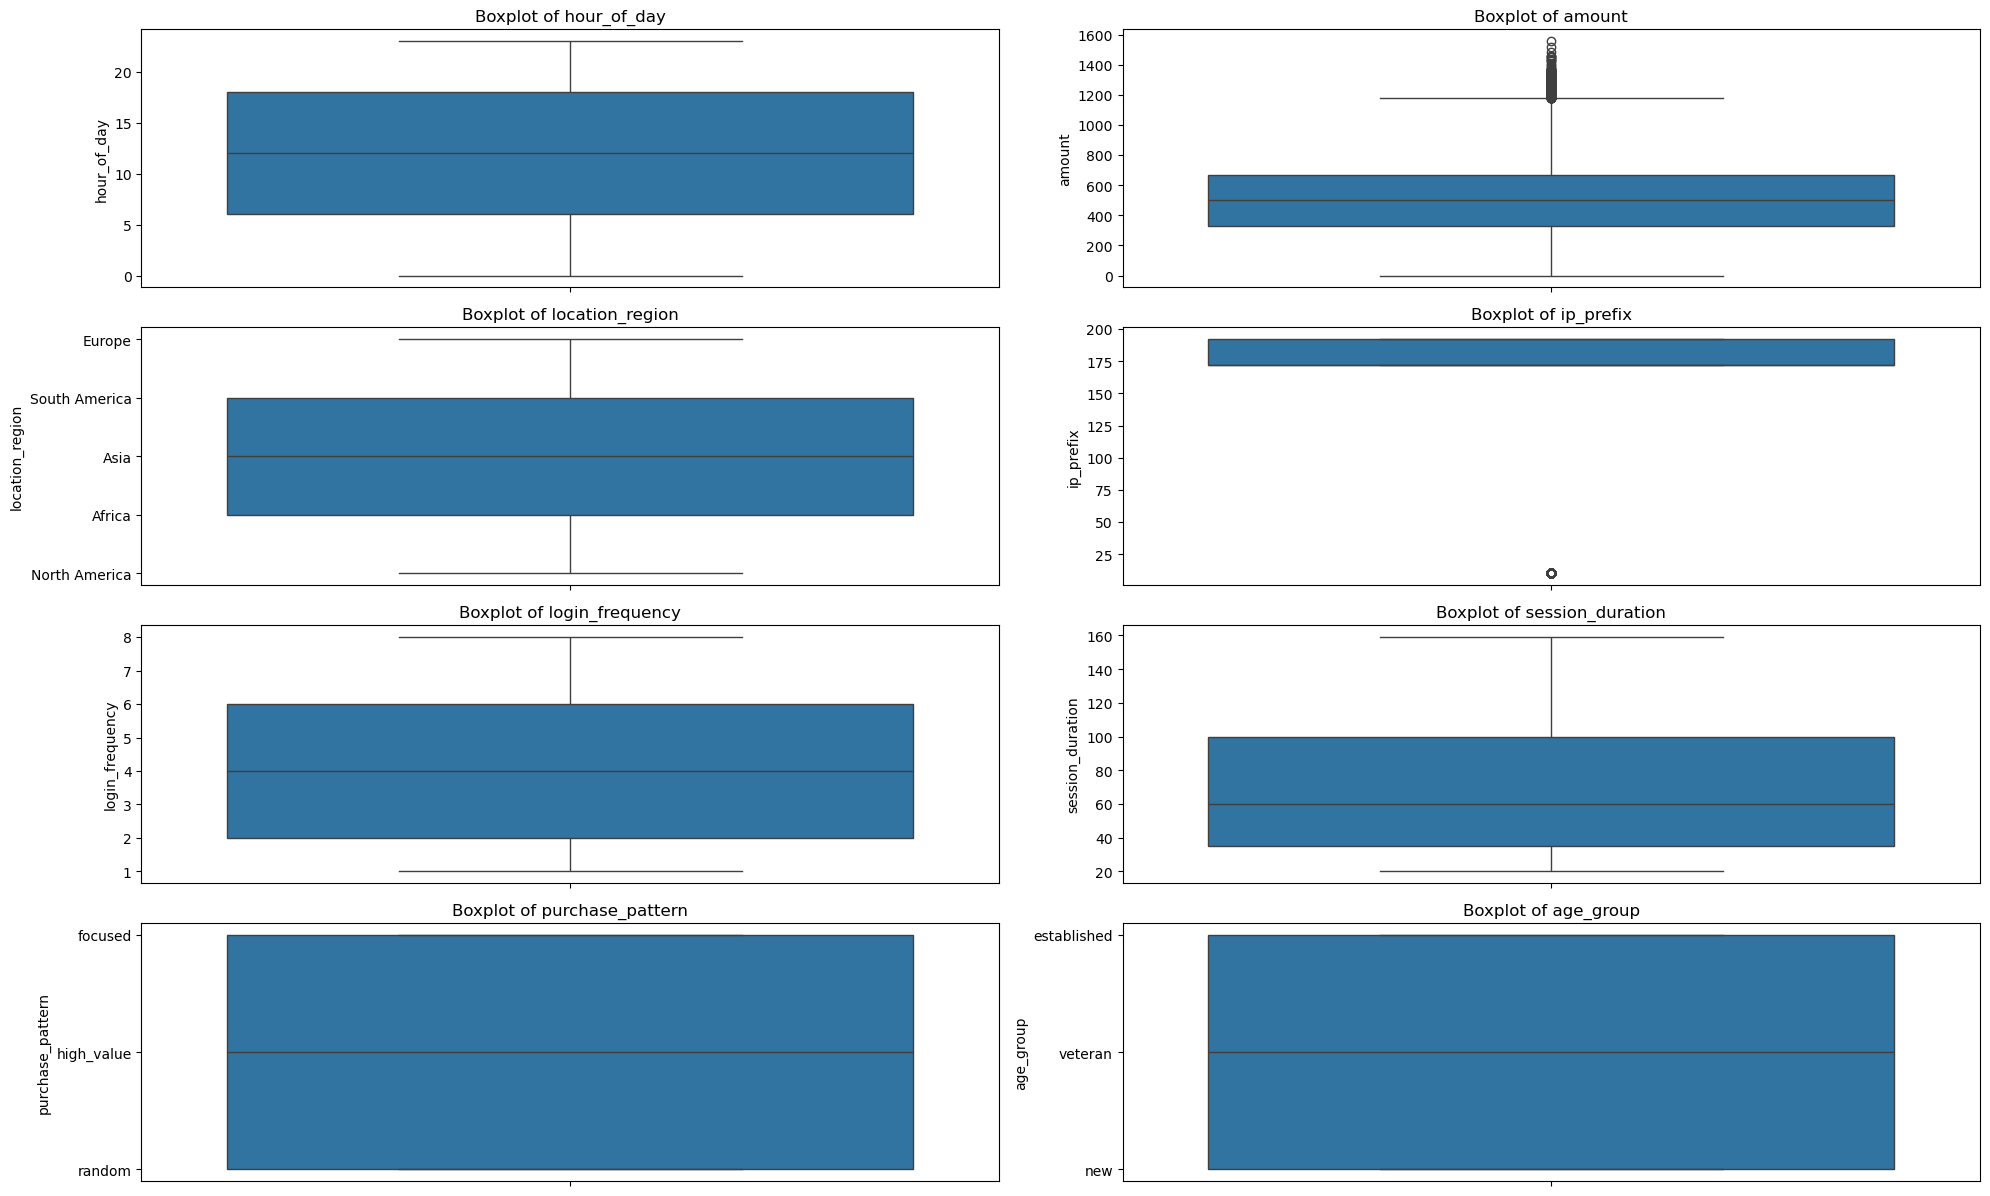

In [14]:
# Extract the first ten columns
X = df.iloc[:, :8]
plt.figure(figsize=(20, 15))

for i, column in enumerate(X.columns, 1):
    plt.subplot(5, 2, i)
    sns.boxplot(y=X[column])
    plt.title(f'Boxplot of {column}')
    plt.tight_layout()

plt.show()

In [15]:
columns_to_check = ['amount', 'ip_prefix']

# Calculate the first quartile (Q1) and third quartile (Q3) for specific columns
Q1 = df[columns_to_check].quantile(0.25)
Q3 = df[columns_to_check].quantile(0.75)
IQR = Q3 - Q1

# Calculate the lower and upper bound for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the dataset to remove outliers
df = df.copy()
for column in columns_to_check:
    df = df[(df[column] >= lower_bound[column]) & (df[column] <= upper_bound[column])]

# Display the filtered dataset
print(df.info())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
Index: 62648 entries, 0 to 78599
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   hour_of_day       62648 non-null  int64  
 1   amount            62648 non-null  float64
 2   location_region   62648 non-null  object 
 3   ip_prefix         62648 non-null  float64
 4   login_frequency   62648 non-null  int64  
 5   session_duration  62648 non-null  int64  
 6   purchase_pattern  62648 non-null  object 
 7   age_group         62648 non-null  object 
 8   anomaly           62648 non-null  object 
dtypes: float64(2), int64(3), object(4)
memory usage: 4.8+ MB
None
   hour_of_day      amount location_region  ip_prefix  login_frequency  \
0           12  796.949206          Europe    192.000                3   
1           19    0.010000   South America    172.000                5   
2           16  778.197390            Asia    192.168                3   
3            9  3

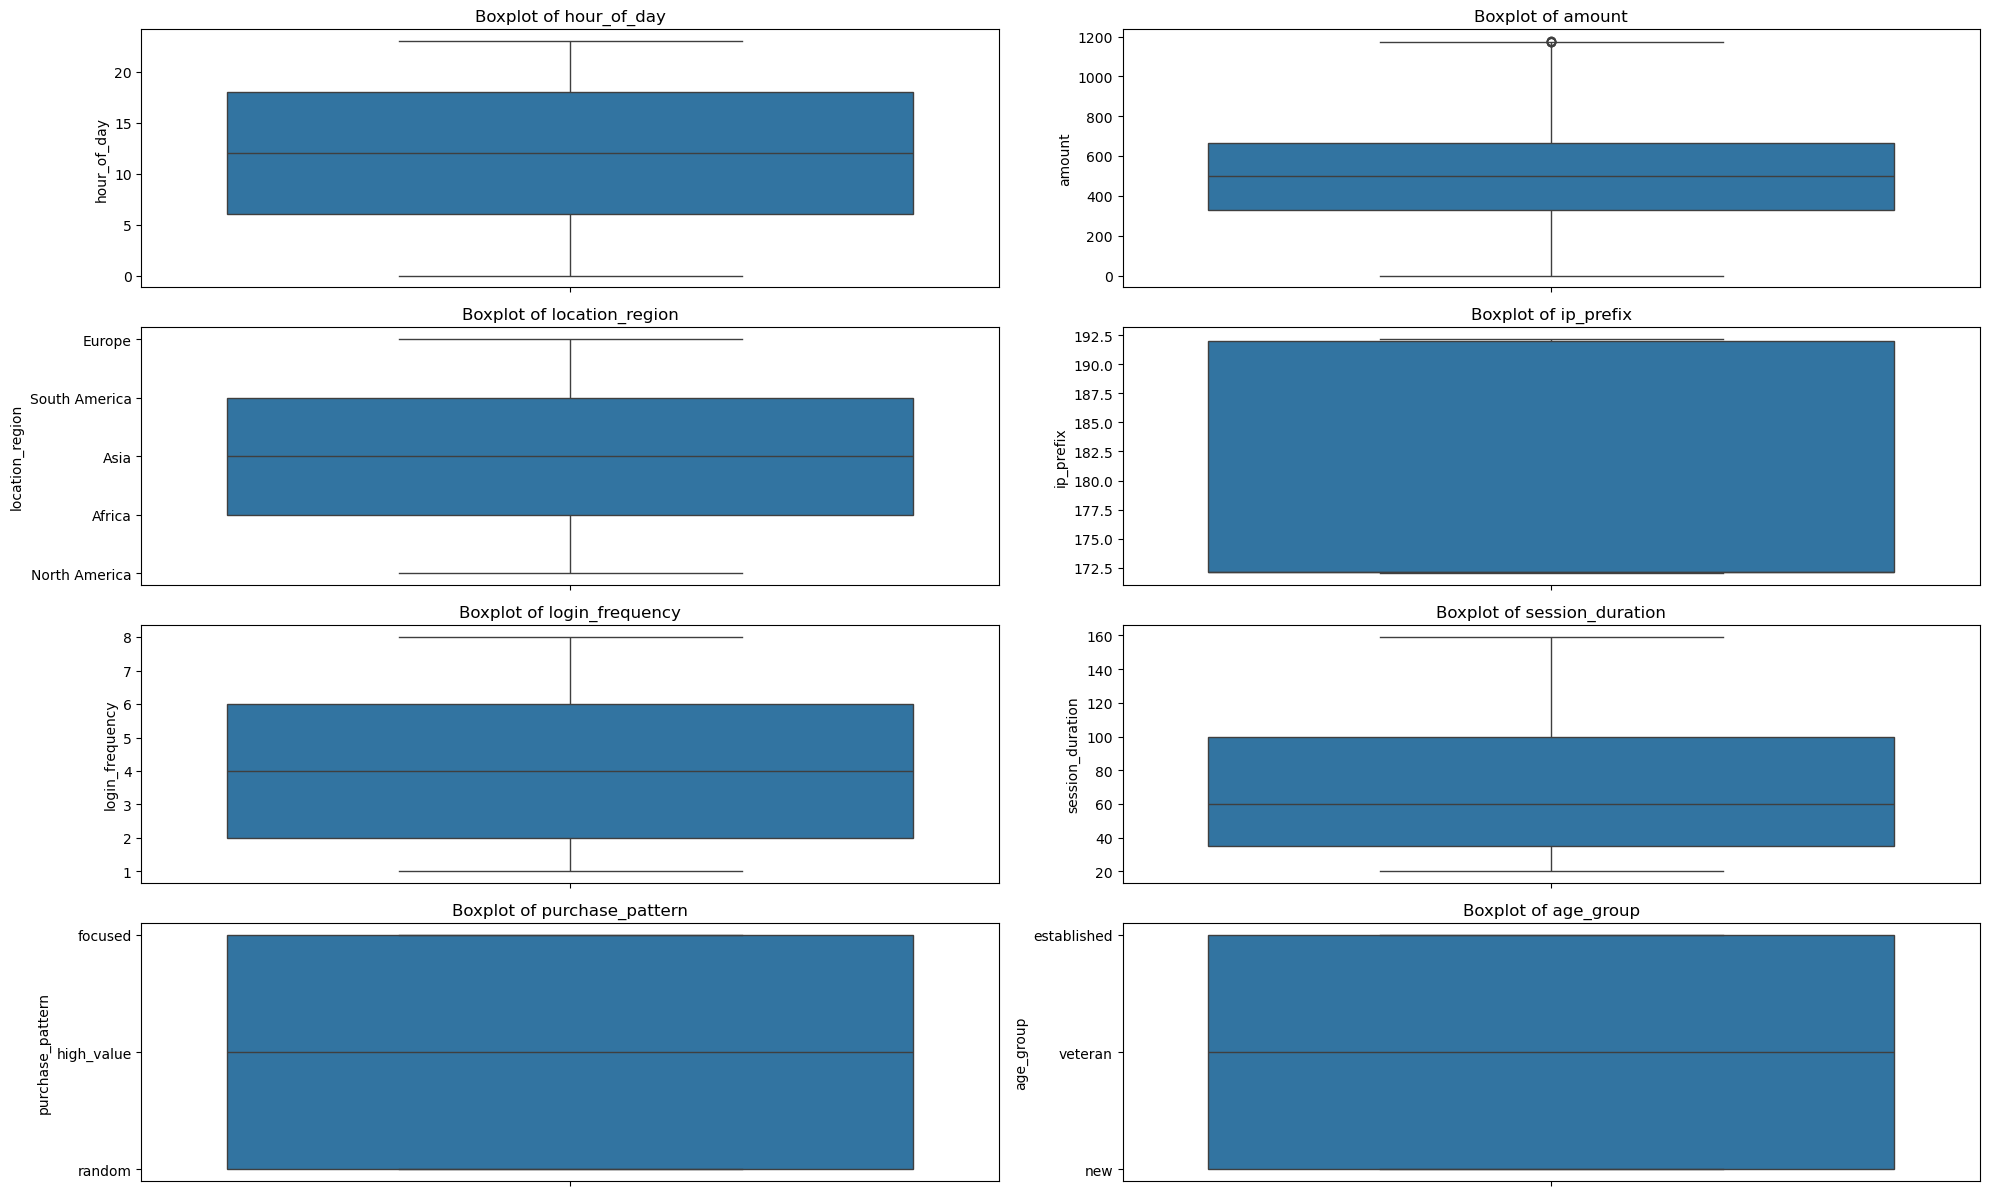

In [16]:
# Extract the first ten columns
X = df.iloc[:, 0:8]
plt.figure(figsize=(20, 15))

for i, column in enumerate(X.columns, 1):
    plt.subplot(5, 2, i)
    sns.boxplot(y=X[column])
    plt.title(f'Boxplot of {column}')
    plt.tight_layout()

plt.show()

In [17]:
df.isnull().sum()

hour_of_day         0
amount              0
location_region     0
ip_prefix           0
login_frequency     0
session_duration    0
purchase_pattern    0
age_group           0
anomaly             0
dtype: int64

In [18]:
# ONE-HOT ENCODING: after mapping and exploratory cleaning, before training
# The anomaly column is the classification target and is NOT one-hot encoded.
categorical_columns = ['location_region', 'purchase_pattern', 'age_group']
df = pd.get_dummies(df, columns=categorical_columns, dtype=int)
print('Encoded shape:', df.shape)
print(df.head())

Encoded shape: (62648, 17)
   hour_of_day      amount  ip_prefix  login_frequency  session_duration  \
0           12  796.949206    192.000                3                48   
1           19    0.010000    172.000                5                61   
2           16  778.197390    192.168                3                74   
3            9  300.838358    172.000                8               111   
4           14  775.569344    172.160                6               100   

         anomaly  location_region_Africa  location_region_Asia  \
0       low_risk                       0                     0   
1       low_risk                       0                     0   
2       low_risk                       0                     1   
3       low_risk                       0                     0   
4  moderate_risk                       1                     0   

   location_region_Europe  location_region_North America  \
0                       1                              0   

In [19]:
# All encoded feature columns, excluding target
X = df.drop(columns=['anomaly'])
Y = df['anomaly']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42, stratify=Y)

In [20]:
 # Standardize the feature matrix
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [21]:
 # Initialize and train the logistic regression model
classifier = LogisticRegression()
classifier.fit(X_train, Y_train)


LogisticRegression()

In [22]:
  # Predict on the test set
y_pred = classifier.predict(X_test)

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Assuming `classifier` is already defined and fitted
y_pred = classifier.predict(X_test)

accuracy_LR = accuracy_score(Y_test, y_pred)
precision_LR = precision_score(Y_test, y_pred, average='micro')  
recall_LR = recall_score(Y_test, y_pred, average='micro')
f1_LR = f1_score(Y_test, y_pred, average='micro')

print("ACCURACY SCORE : ", accuracy_LR)
print("PRECISION SCORE : ", precision_LR)
print("RECALL SCORE : ", recall_LR)
print("F1 SCORE : ", f1_LR)
print(classification_report(Y_test, y_pred))


ACCURACY SCORE :  0.8352700804494956
PRECISION SCORE :  0.8352700804494956
RECALL SCORE :  0.8352700804494956
F1 SCORE :  0.8352700804494956
               precision    recall  f1-score   support

    high_risk       0.00      0.00      0.00      1310
     low_risk       0.85      0.97      0.90     12646
moderate_risk       0.67      0.50      0.57      1706

     accuracy                           0.84     15662
    macro avg       0.51      0.49      0.49     15662
 weighted avg       0.76      0.84      0.79     15662



C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [24]:
from sklearn.tree import DecisionTreeClassifier

In [25]:
treemodel = DecisionTreeClassifier(max_depth = 2)
treemodel

DecisionTreeClassifier(max_depth=2)

In [26]:
treemodel.fit(X_train,Y_train)

DecisionTreeClassifier(max_depth=2)

[Text(0.5, 0.8333333333333334, 'x[15] <= 0.339\ngini = 0.329\nsamples = 46986\nvalue = [3931, 37938, 5117]'),
 Text(0.25, 0.5, 'x[14] <= 0.359\ngini = 0.235\nsamples = 31040\nvalue = [3931, 26869, 240]'),
 Text(0.125, 0.16666666666666666, 'gini = 0.0\nsamples = 15483\nvalue = [0, 15483, 0]'),
 Text(0.375, 0.16666666666666666, 'gini = 0.4\nsamples = 15557\nvalue = [3931.0, 11386.0, 240.0]'),
 Text(0.75, 0.5, 'x[0] <= -0.727\ngini = 0.425\nsamples = 15946\nvalue = [0, 11069, 4877]'),
 Text(0.625, 0.16666666666666666, 'gini = 0.421\nsamples = 4537\nvalue = [0, 1366, 3171]'),
 Text(0.875, 0.16666666666666666, 'gini = 0.254\nsamples = 11409\nvalue = [0, 9703, 1706]')]

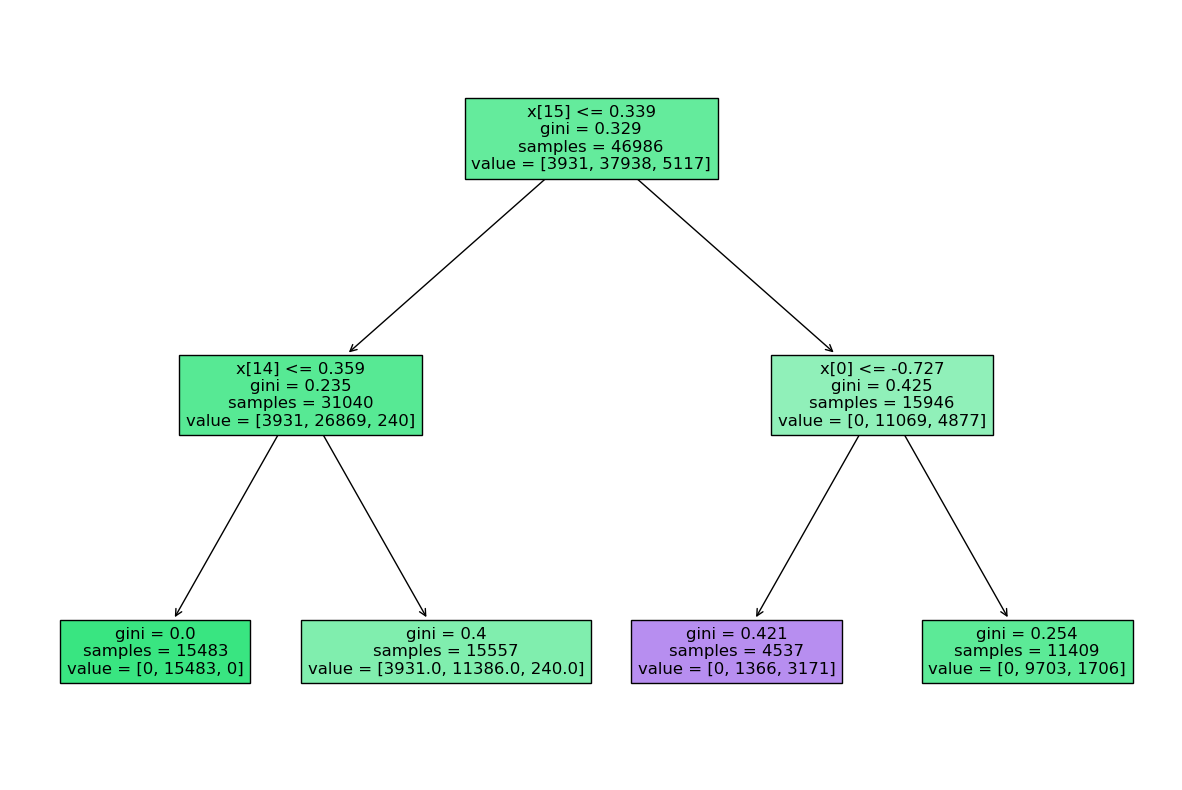

In [27]:
import matplotlib.pyplot as plt
from sklearn import tree

plt.figure(figsize = (15,10))
tree.plot_tree(treemodel,filled = True)

In [28]:
treemodel = DecisionTreeClassifier()
treemodel

DecisionTreeClassifier()

In [29]:
treemodel.fit(X_train,Y_train)

DecisionTreeClassifier()

In [76]:
from sklearn import tree
plt.figure(figsize = (10,15))
tree.plot_tree(treemodel,filled = True)

RandomForestClassifier(max_depth=10, n_jobs=-1, random_state=42)

In [78]:
y_pred1 = treemodel.predict(X_test)
y_pred1

array(['low_risk', 'low_risk', 'low_risk', ..., 'moderate_risk',
       'low_risk', 'high_risk'], dtype=object)

In [80]:
from sklearn.metrics import accuracy_score,classification_report 

In [82]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
accuracy_DT = accuracy_score(Y_test,y_pred1)
precision_DT = precision_score(Y_test,y_pred1,average='micro')
recall_DT = recall_score(Y_test,y_pred1,average='micro')
f1_DT = f1_score(Y_test,y_pred1,average='micro')
print("ACCURACY SCORE : ", accuracy_DT)
print(classification_report(Y_test,y_pred1))

ACCURACY SCORE :  0.8040480143021326
               precision    recall  f1-score   support

    high_risk       0.26      0.28      0.27      1310
     low_risk       0.88      0.88      0.88     12646
moderate_risk       0.69      0.65      0.67      1706

     accuracy                           0.80     15662
    macro avg       0.61      0.60      0.61     15662
 weighted avg       0.81      0.80      0.81     15662



In [115]:
from sklearn.ensemble import RandomForestClassifier

forestmodel = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

forestmodel.fit(X_train, Y_train)

RandomForestClassifier(max_depth=12, n_jobs=-1, random_state=42)

In [116]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Train the model
forestmodel.fit(X_train, Y_train)

# Make predictions
y_pred_rf = forestmodel.predict(X_test)

# Calculate performance metrics
accuracy_RF = accuracy_score(Y_test, y_pred_rf)
precision_RF = precision_score(Y_test, y_pred_rf, average='weighted')
recall_RF = recall_score(Y_test, y_pred_rf, average='weighted')
f1_RF = f1_score(Y_test, y_pred_rf, average='weighted')

conf_matrix_rf = confusion_matrix(Y_test, y_pred_rf)
class_report_rf = classification_report(Y_test, y_pred_rf)

# Print the performance metrics for Random Forest
print('Random Forest Metrics:')
print('Accuracy:',accuracy_RF)
print('Precision:',precision_RF)
print('Recall:',recall_RF)
print('F1-Score:',f1_RF)
print('Confusion Matrix:\n',conf_matrix_rf)
print('Classification Report: \n', class_report_rf)


Random Forest Metrics:
Accuracy: 0.8692376452560338
Precision: 0.8289016786347374
Recall: 0.8692376452560338
F1-Score: 0.8329166939155161
Confusion Matrix:
 [[    2  1308     0]
 [    3 11995   648]
 [    1    88  1617]]
Classification Report: 
                precision    recall  f1-score   support

    high_risk       0.33      0.00      0.00      1310
     low_risk       0.90      0.95      0.92     12646
moderate_risk       0.71      0.95      0.81      1706

     accuracy                           0.87     15662
    macro avg       0.65      0.63      0.58     15662
 weighted avg       0.83      0.87      0.83     15662



In [43]:
from sklearn.neighbors import KNeighborsClassifier
knn =  KNeighborsClassifier(n_neighbors = 3)

In [44]:
knn.fit(X_train,Y_train)
y_predknn = knn.predict(X_test)

C:\Users\ASUS\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\ASUS\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\ASUS\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ASUS\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\ASUS\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

In [45]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
y_predknn = knn.predict(X_test)
nvb_accuracy = accuracy_score(Y_test,y_predknn)
nvb_precision = precision_score(Y_test,y_predknn,average='micro')
nvb_recall = recall_score(Y_test,y_predknn,average='micro')
nvb_f1 = f1_score(Y_test,y_predknn,average='micro')
print("ACCURACY SCORE : ", nvb_accuracy)
print(classification_report(Y_test,y_pred))

ACCURACY SCORE :  0.8203933086451284
               precision    recall  f1-score   support

    high_risk       0.00      0.00      0.00      1310
     low_risk       0.85      0.97      0.90     12646
moderate_risk       0.67      0.50      0.57      1706

     accuracy                           0.84     15662
    macro avg       0.51      0.49      0.49     15662
 weighted avg       0.76      0.84      0.79     15662



C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [46]:
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()

#fitting-
gnb.fit(X_train, Y_train)
#predicting
y_pred2=gnb.predict(X_test)

In [47]:
#importing libraries
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score

#scores
acc_score_gnb = accuracy_score(y_pred2, Y_test)
recall_scr_gnb = recall_score(y_pred2, Y_test, average='weighted')
pre_scr_gnb = precision_score(y_pred2, Y_test, average='weighted')
f1_scr_gnb = f1_score(y_pred, Y_test, average='weighted')
class_report = classification_report(y_pred2, Y_test)

print('Accuracy score is:\n', acc_score_gnb, '\n')
print('Recall score is:\n', recall_scr_gnb, '\n')
print('Precision score is:\n', pre_scr_gnb, '\n')
print('F1 score is:\n', f1_scr_gnb, '\n')
print('Classification report is:\n', class_report)


Accuracy score is:
 0.5234963606180565 

Recall score is:
 0.5234963606180565 

Precision score is:
 0.7900476142300367 

F1 score is:
 0.8776103609047126 

Classification report is:
                precision    recall  f1-score   support

    high_risk       1.00      0.25      0.40      5266
     low_risk       0.42      1.00      0.59      5255
moderate_risk       0.96      0.32      0.48      5141

     accuracy                           0.52     15662
    macro avg       0.79      0.52      0.49     15662
 weighted avg       0.79      0.52      0.49     15662



In [48]:
forestmodel.predict(scaler.transform(X.iloc[[0]]))

array(['low_risk'], dtype=object)

In [49]:
treemodel.predict(scaler.transform(X.iloc[[0]]))

array(['low_risk'], dtype=object)

In [50]:
classifier.predict(scaler.transform(X.iloc[[0]]))

array(['low_risk'], dtype=object)

In [51]:
gnb.predict(scaler.transform(X.iloc[[0]]))

array(['low_risk'], dtype='<U13')

In [52]:
knn.predict(scaler.transform(X.iloc[[0]]))

array(['low_risk'], dtype=object)

In [72]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# X_train and X_test are already scaled above; do not scale twice.

# Train a Support Vector Classifier
clf = SVC(kernel='linear')
clf.fit(X_train, Y_train)

# Make predictions
y_predsvc = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(Y_test, y_predsvc)
print(f"Accuracy: {accuracy:.2f}")


print(classification_report(Y_test, y_pred))
print(confusion_matrix(Y_test, y_pred))

Accuracy: 0.84
               precision    recall  f1-score   support

    high_risk       0.00      0.00      0.00      1310
     low_risk       0.85      0.97      0.90     12646
moderate_risk       0.67      0.50      0.57      1706

     accuracy                           0.84     15662
    macro avg       0.51      0.49      0.49     15662
 weighted avg       0.76      0.84      0.79     15662

[[    0  1310     0]
 [    0 12225   421]
 [    0   849   857]]


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [119]:
import joblib

best_model = forestmodel

joblib.dump(best_model, "metaverse_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "feature_columns.pkl")

print("Model and preprocessing files saved!")

Model and preprocessing files saved!


In [121]:
import joblib

joblib.dump(forestmodel, "metaverse_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "feature_columns.pkl")

print("Deployment files saved successfully!")

Deployment files saved successfully!


In [56]:

comparison_table = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN', 'GaussianNB', 'SVC'],
    'Accuracy': [accuracy_LR, accuracy_DT, accuracy_RF, nvb_accuracy, acc_score_gnb, accuracy]
})

# Round accuracy values to 2 decimal places
comparison_table['Accuracy'] = comparison_table['Accuracy'].round(2)

print(comparison_table)

                 Model  Accuracy
0  Logistic Regression      0.84
1        Decision Tree      0.80
2        Random Forest      0.85
3                  KNN      0.82
4           GaussianNB      0.52
5                  SVC      0.84


In [57]:
prediction_table = pd.DataFrame({
    'True Value': Y_test,
    'Logistic Regression Prediction': y_pred,
    'Decision Tree Prediction': y_pred1,
    'Random Forest Prediction': y_pred_rf,
    'K-Neighbor': y_predknn,
    'GausianNB': y_pred2,
    'SVC':y_predsvc
})
print(prediction_table)

          True Value Logistic Regression Prediction Decision Tree Prediction  \
37815       low_risk                       low_risk                 low_risk   
37029       low_risk                       low_risk                 low_risk   
6985        low_risk                       low_risk                 low_risk   
36191      high_risk                       low_risk                 low_risk   
72225       low_risk                       low_risk                 low_risk   
...              ...                            ...                      ...   
77248  moderate_risk                  moderate_risk            moderate_risk   
19878      high_risk                       low_risk                 low_risk   
37424  moderate_risk                  moderate_risk            moderate_risk   
49080       low_risk                       low_risk                 low_risk   
44473      high_risk                       low_risk                high_risk   

      Random Forest Prediction     K-Ne

In [58]:
clf.predict(scaler.transform(X.iloc[[0]]))

array(['low_risk'], dtype=object)

Skewness of hour_of_day: -0.003568430780016973


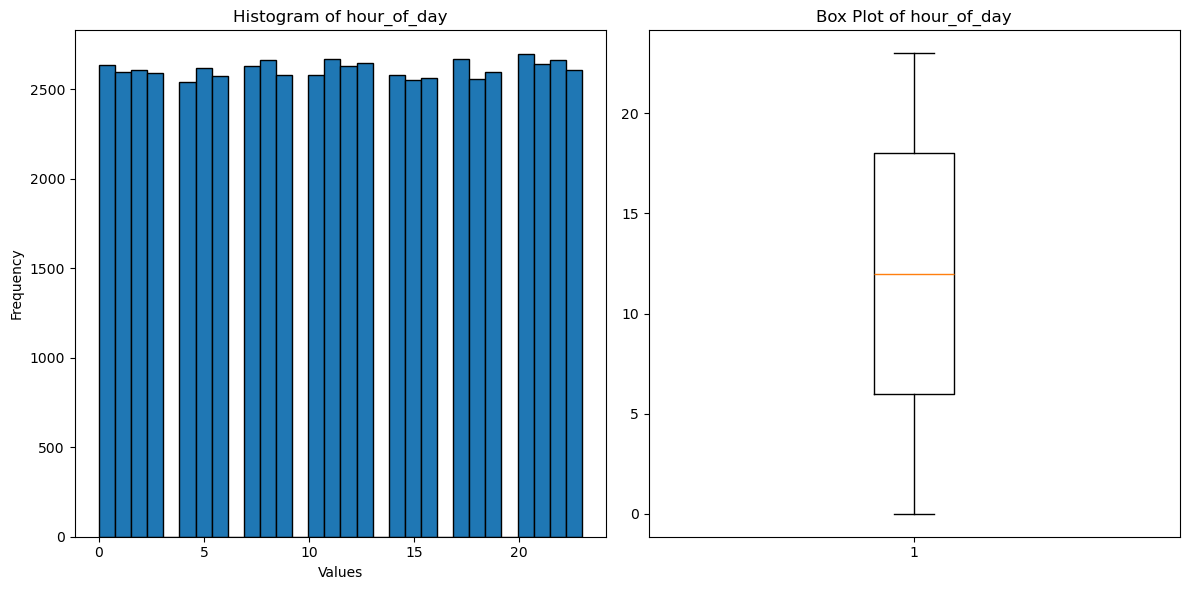

Skewness of amount: 0.05572288330501218


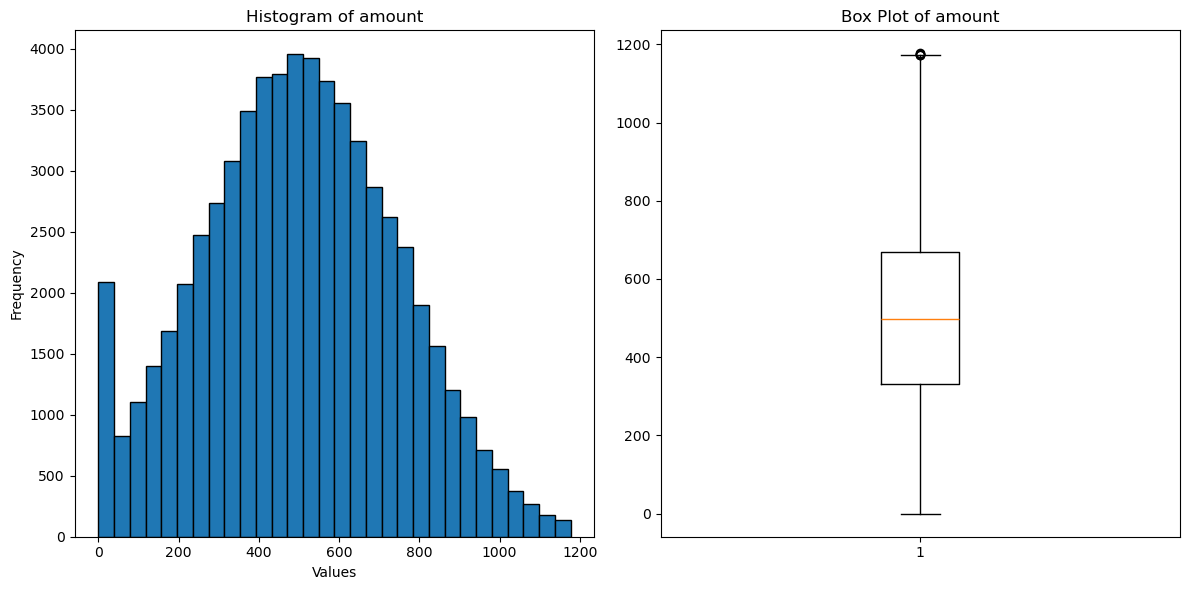

Skewness of ip_prefix: 0.008054038752133277


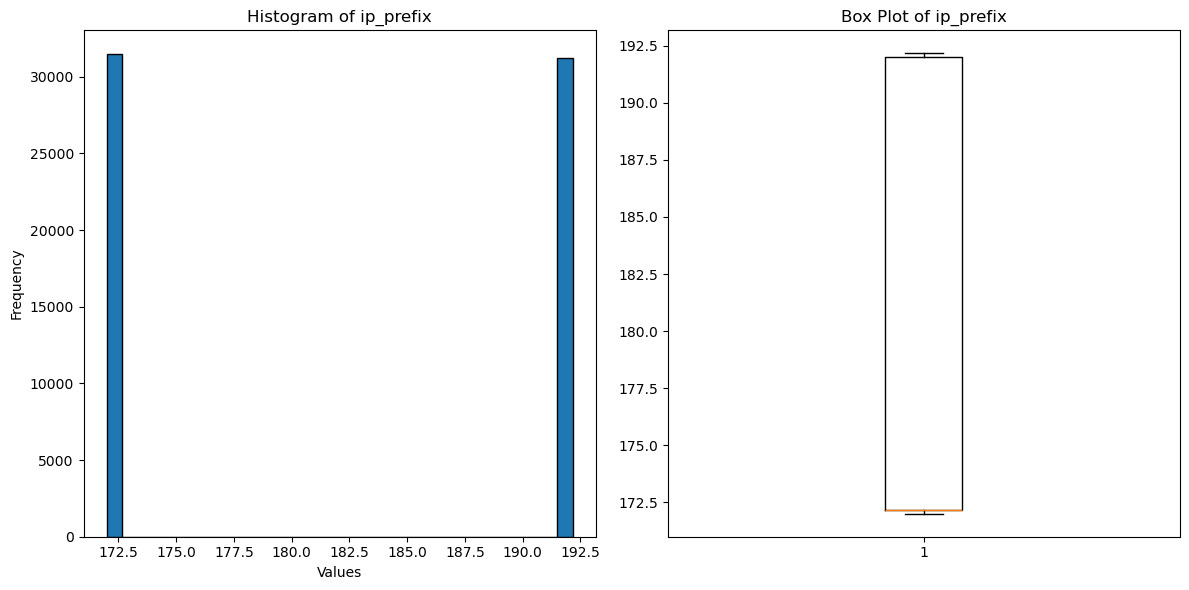

Skewness of login_frequency: 0.17366008875401437


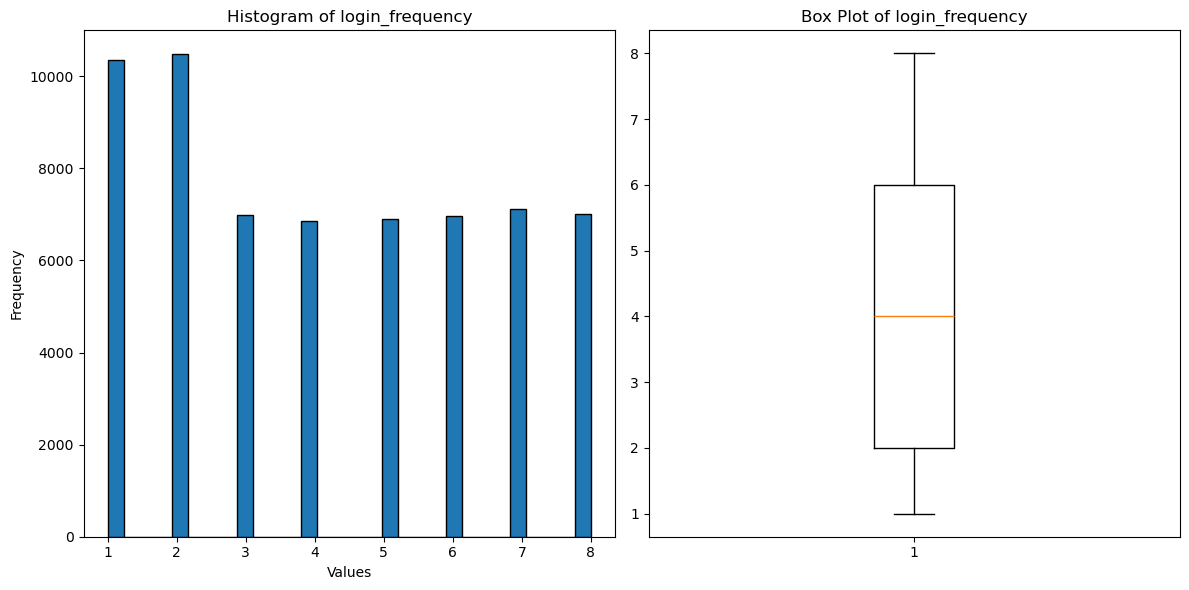

Skewness of session_duration: 0.659334013473066


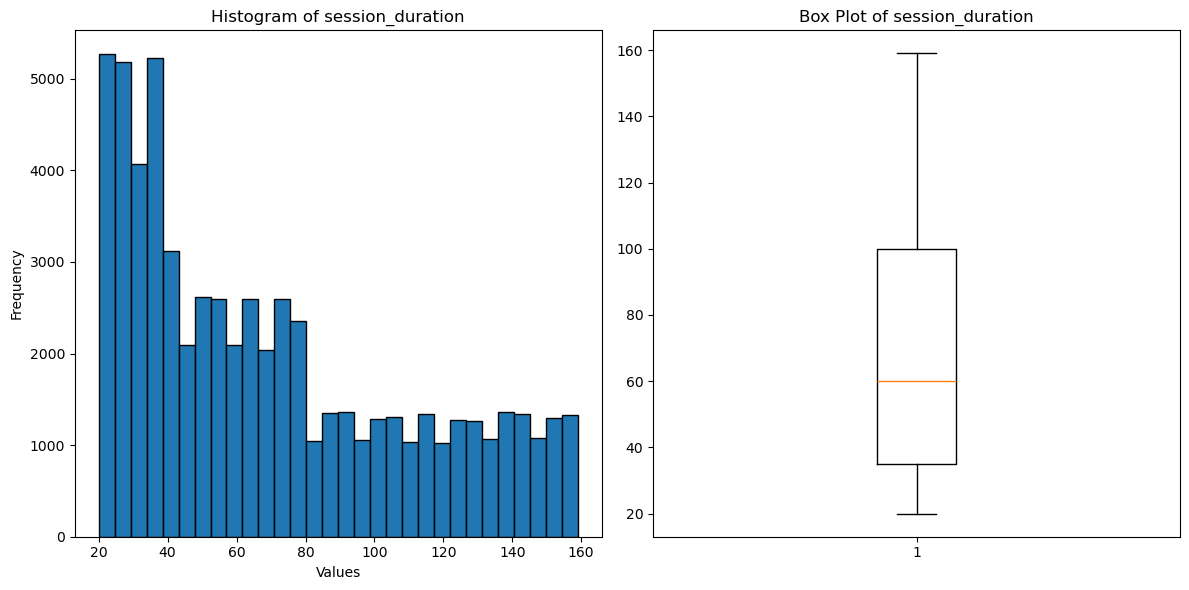

TypeError: unsupported operand type(s) for /: 'str' and 'int'

In [61]:
import matplotlib.pyplot as plt
from scipy.stats import skew

# List of columns to analyze
columns = df.columns[:9]  # Assuming you want to analyze the first 9 columns

# Plotting histograms and box plots for each column
for column in columns:
    # Calculate skewness
    skewness = skew(df[column])
    print(f'Skewness of {column}: {skewness}')

    # Plot histogram
    plt.figure(figsize=(12, 6))
    
    plt.subplot(1, 2, 1)  # 1 row, 2 columns, first subplot
    plt.hist(df[column], bins=30, edgecolor='black')
    plt.title(f'Histogram of {column}')
    plt.xlabel('Values')
    plt.ylabel('Frequency')
    
    # Plot box plot
    plt.subplot(1, 2, 2)  # 1 row, 2 columns, second subplot
    plt.boxplot(df[column])
    plt.title(f'Box Plot of {column}')
    
    # Show plots
    plt.tight_layout()
    plt.show()


In [62]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'GaussianNB': GaussianNB(),
    'SVC': SVC()
}

In [68]:
from sklearn.metrics import accuracy_score

for name, model in models.items():
    model.fit(X_train, Y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    print(
        name,
        "Train:", round(accuracy_score(Y_train, train_pred), 4),
        "Test:", round(accuracy_score(Y_test, test_pred), 4)
    )

Logistic Regression Train: 0.8346 Test: 0.8353
Decision Tree Train: 0.9999 Test: 0.8026
Random Forest Train: 0.9999 Test: 0.8477
KNN Train: 0.8805 Test: 0.8303
GaussianNB Train: 0.517 Test: 0.5235
SVC Train: 0.8526 Test: 0.8551
